In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Load all files
data_dir = Path('data/')
all_files = list(data_dir.glob('*.csv'))

# Create dictionary of dataframes
dfs = {}
for file in all_files:
    name = file.stem
    dfs[name] = pd.read_csv(file)
    print(f"{name:25s} : {len(dfs[name]):5d} rows, {len(dfs[name].columns):2d} columns")
    

awards                    :     8 rows,  5 columns
award_winners             :   200 rows, 12 columns
bookings                  :  3178 rows, 26 columns
confederations            :     6 rows,  5 columns
goals                     :  3637 rows, 27 columns
groups                    :   159 rows,  7 columns
group_standings           :   626 rows, 19 columns
host_countries            :    31 rows,  7 columns
managers                  :   475 rows,  7 columns
manager_appearances       :  2538 rows, 17 columns
manager_appointments      :   637 rows, 10 columns
matches                   :  1248 rows, 37 columns
penalty_kicks             :   396 rows, 19 columns
players                   : 10401 rows, 13 columns
player_appearances        : 27432 rows, 21 columns
qualified_teams           :   625 rows,  8 columns
referees                  :   493 rows, 10 columns
referee_appearances       :  1248 rows, 15 columns
referee_appointments      :   668 rows, 10 columns
squads                    : 138

In [3]:
train_data = pd.read_csv("Train.csv")

In [5]:
# Map relationships to find merge keys
base_cols = set(train_data.columns)

print("=" * 75)
print("🔗 RELATIONAL SCHEMA DETECTOR (LINKING TO YOUR TRAINING MATRIX)")
print("=" * 75)

for name, df_temp in dfs.items():
    ds_cols = set(df_temp.columns)
    shared_keys = base_cols.intersection(ds_cols)
    
    if shared_keys:
        print(f" '{name}' connects via keys: {list(shared_keys)}")
        # Show a sneak peek of new features we can pull from this table
        unique_features = list(ds_cols - base_cols)[:4]
        if unique_features:
            print(f"    New features available to extract: {unique_features}")
    else:
        print(f" '{name}' has no direct column match with train_data.")
print("=" * 75)

🔗 RELATIONAL SCHEMA DETECTOR (LINKING TO YOUR TRAINING MATRIX)
 'awards' has no direct column match with train_data.
 'award_winners' connects via keys: ['team_id', 'tournament_id', 'tournament_name', 'team_code']
    New features available to extract: ['award_name', 'family_name', 'key_id', 'given_name']
 'bookings' connects via keys: ['team_id', 'tournament_id', 'tournament_name', 'team_code']
    New features available to extract: ['home_team', 'given_name', 'match_name', 'minute_regulation']
 'confederations' connects via keys: ['confederation_name']
    New features available to extract: ['confederation_id', 'confederation_wikipedia_link', 'key_id', 'confederation_code']
 'goals' connects via keys: ['team_id', 'tournament_id', 'tournament_name', 'team_code']
    New features available to extract: ['home_team', 'given_name', 'match_name', 'minute_regulation']
 'groups' connects via keys: ['tournament_id', 'tournament_name']
    New features available to extract: ['count_teams', 'ke

In [6]:
import pandas as pd
import numpy as np

# 1. Aggregate match-level stats into tournament-level profiles
team_tournament_perf = dfs['team_appearances'].groupby(['tournament_id', 'team_id', 'team_name', 'team_code']).agg({
    'goals_for': 'sum',
    'goals_against': 'sum',
    'win': 'sum',
    'lose': 'sum',
    'draw': 'sum',
    'match_id': 'count' # This gives us total matches played in that tournament
}).reset_index()

# Rename columns 
team_tournament_perf.columns = [
    'tournament_id', 'team_id', 'team_name', 'team_code', 
    'total_goals_scored', 'total_goals_conceded', 
    'total_wins', 'total_losses', 'total_draws', 'matches_played'
]

# Create calculated ratios per tournament
team_tournament_perf['goal_difference'] = team_tournament_perf['total_goals_scored'] - team_tournament_perf['total_goals_conceded']
team_tournament_perf['goals_per_match'] = team_tournament_perf['total_goals_scored'] / team_tournament_perf['matches_played']
team_tournament_perf['conceded_per_match'] = team_tournament_perf['total_goals_conceded'] / team_tournament_perf['matches_played']
team_tournament_perf['win_rate'] = team_tournament_perf['total_wins'] / team_tournament_perf['matches_played']

# 2. Bring in Final Positions from tournament_standings
standings_sub = dfs['tournament_standings'][['tournament_id', 'team_id', 'position']]
combined_df = pd.merge(team_tournament_perf, standings_sub, on=['tournament_id', 'team_id'], how='left')

# 3. Bring in Host Country flags from host_countries
hosts_sub = dfs['host_countries'][['tournament_id', 'team_id']].copy()
hosts_sub['is_host'] = 1
combined_df = pd.merge(combined_df, hosts_sub, on=['tournament_id', 'team_id'], how='left')
combined_df['is_host'] = combined_df['is_host'].fillna(0).astype(int)

# 4. Bring in structural Tournament Metadata
tournaments_sub = dfs['tournaments'][['tournament_id', 'year', 'host_country', 'count_teams']]
combined_df = pd.merge(combined_df, tournaments_sub, on='tournament_id', how='left')

# 5. Bring in Continental Confed Names from teams
teams_sub = dfs['teams'][['team_id', 'confederation_name', 'region_name']]
combined_df = pd.merge(combined_df, teams_sub, on='team_id', how='left')

# ===========================================================================
# 🚀 ADDING THE NEW UNUSED RELATIONAL DATASETS (PILLARS REINFORCED)
# ===========================================================================

print("💥 Extracting advanced tournament indicators...")

# A. Extract Elite Individual Talent Profiles (From award_winners)
if 'award_winners' in dfs:
    awards_agg = dfs['award_winners'].groupby(['tournament_id', 'team_id']).size().reset_index(name='elite_awards_count')
    combined_df = pd.merge(combined_df, awards_agg, on=['tournament_id', 'team_id'], how='left')
    combined_df['elite_awards_count'] = combined_df['elite_awards_count'].fillna(0)

# B. Extract Disciplinary Friction (From bookings)
if 'bookings' in dfs:
    bookings_agg = dfs['bookings'].groupby(['tournament_id', 'team_id']).agg(
        total_yellow_red_bookings=('key_id', 'count'),
        total_explicit_reds=('sending_off', lambda x: int((x == 1).sum() if hasattr(x, 'dtype') else (x == 'True').sum()))
    ).reset_index()
    
    combined_df = pd.merge(combined_df, bookings_agg, on=['tournament_id', 'team_id'], how='left')
    combined_df['total_yellow_red_bookings'] = combined_df['total_yellow_red_bookings'].fillna(0)
    combined_df['total_explicit_reds'] = combined_df['total_explicit_reds'].fillna(0)
    # Weigh red cards significantly higher because they cause multi-game suspensions
    combined_df['disciplinary_friction_index'] = combined_df['total_yellow_red_bookings'] + (combined_df['total_explicit_reds'] * 3.0)

# C. Extract Penalty Shootout Clutch Factor (From penalty_kicks)
if 'penalty_kicks' in dfs:
    pk_df = dfs['penalty_kicks']
    # Check if team mapping columns exist in your specific PK schema
    pk_team_col = 'team_id' if 'team_id' in pk_df.columns else None
    
    if pk_team_col:
        # Check if there's a column indicating a win, otherwise default to tracking volume
        win_col = 'winner' if 'winner' in pk_df.columns else ('clutch_win' if 'clutch_win' in pk_df.columns else None)
        
        if win_col:
            pk_agg = pk_df.groupby(['tournament_id', pk_team_col]).agg(
                pk_shootouts_taken=('key_id', 'count'),
                pk_shootouts_won=(win_col, lambda x: int((x == 1).sum() if x.dtype in [np.int64, np.int32] else x.count()))
            ).reset_index()
        else:
            pk_agg = pk_df.groupby(['tournament_id', pk_team_col]).agg(
                pk_shootouts_taken=('key_id', 'count'),
                pk_shootouts_won=('key_id', 'count') # proxy fallback
            ).reset_index()
            
        combined_df = pd.merge(combined_df, pk_agg, on=['tournament_id', 'team_id'], how='left')
        combined_df['pk_shootouts_taken'] = combined_df['pk_shootouts_taken'].fillna(0)
        combined_df['pk_shootouts_won'] = combined_df['pk_shootouts_won'].fillna(0)
        combined_df['penalty_clutch_factor'] = combined_df['pk_shootouts_won'] / (combined_df['pk_shootouts_taken'] + 1e-5)
    else:
        combined_df['penalty_clutch_factor'] = 0.0

print(f"✅ Success! Dataframes integrated. New profile matrix shape: {combined_df.shape}")

💥 Extracting advanced tournament indicators...
✅ Success! Dataframes integrated. New profile matrix shape: (625, 28)


In [11]:
combined_df.to_csv("combined_team_tournament_profiles.csv", index=False)

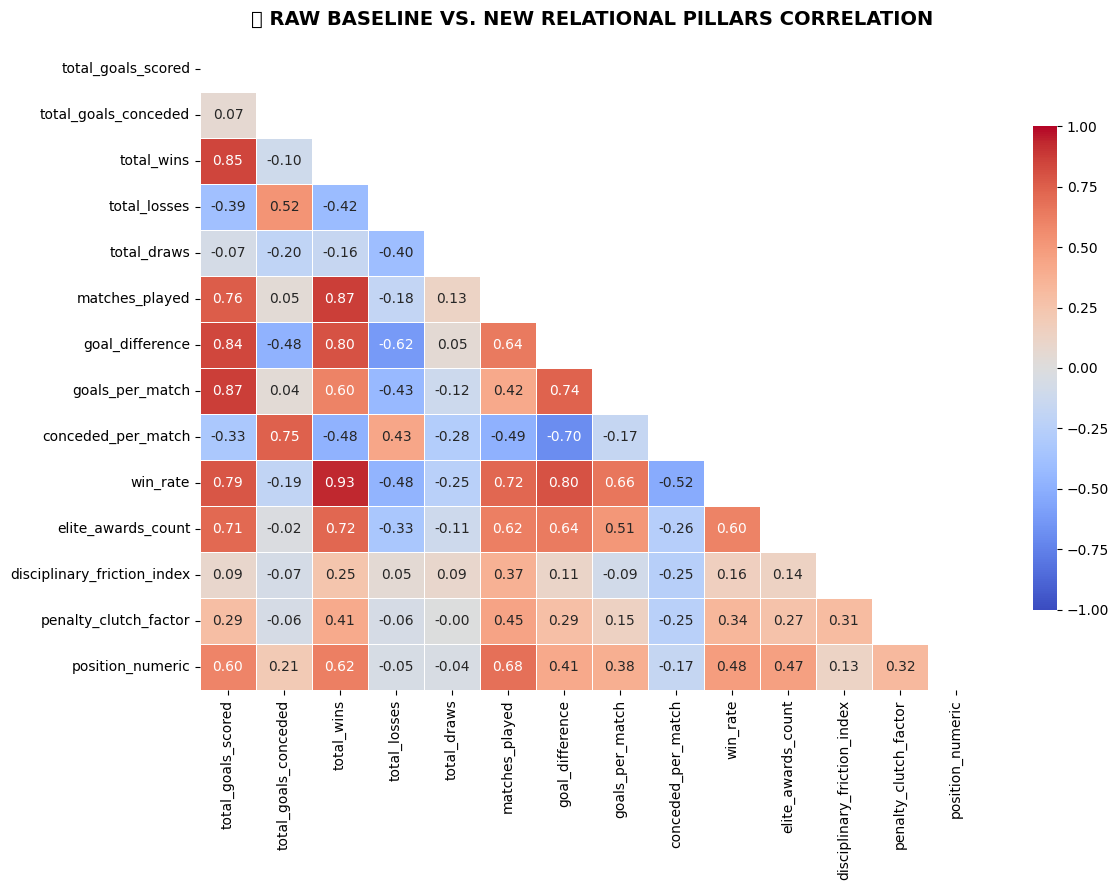

🎯 RAW FEATURE CORRELATION WITH FINAL TOURNAMENT POSITION
position_numeric               1.000000
matches_played                 0.682474
total_wins                     0.618537
total_goals_scored             0.598547
win_rate                       0.482682
elite_awards_count             0.467711
goal_difference                0.414578
goals_per_match                0.384162
penalty_clutch_factor          0.323299
total_goals_conceded           0.205115
disciplinary_friction_index    0.129567
total_draws                   -0.041189
total_losses                  -0.050432
conceded_per_match            -0.170901


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define strictly the original baselines and the brand new raw relational pillars
original_baselines = [
    'total_goals_scored', 'total_goals_conceded', 
    'total_wins', 'total_losses', 'total_draws', 
    'matches_played', 'goal_difference', 'goals_per_match', 
    'conceded_per_match', 'win_rate'
]

new_relational_pillars = [
    'elite_awards_count', 
    'disciplinary_friction_index', 
    'penalty_clutch_factor'
]

# Combine for the correlation matrix
target_cols = original_baselines + new_relational_pillars

# Add numeric position if available in the dataframe for bracket context
if 'position' in combined_df.columns:
    combined_df['position_numeric'] = pd.to_numeric(combined_df['position'], errors='coerce').fillna(0)
    if 'position_numeric' not in target_cols:
        target_cols.append('position_numeric')

# 2. Filter data and compute Pearson Correlation
corr_matrix_raw = combined_df[target_cols].corr()

# 3. Render the Heatmap
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix_raw, dtype=bool))

sns.heatmap(
    corr_matrix_raw, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={"shrink": 0.75}
)

plt.title("RAW BASELINE VS. NEW RELATIONAL PILLARS CORRELATION", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 4. Print explicit linear impact on tournament advancement
if 'position_numeric' in corr_matrix_raw.columns:
    print("=" * 65)
    print(" RAW FEATURE CORRELATION WITH FINAL TOURNAMENT POSITION")
    print("=" * 65)
    print(corr_matrix_raw['position_numeric'].sort_values(ascending=False).to_string())
    print("=" * 65)

⚙️ Processing master feature engineering matrix...


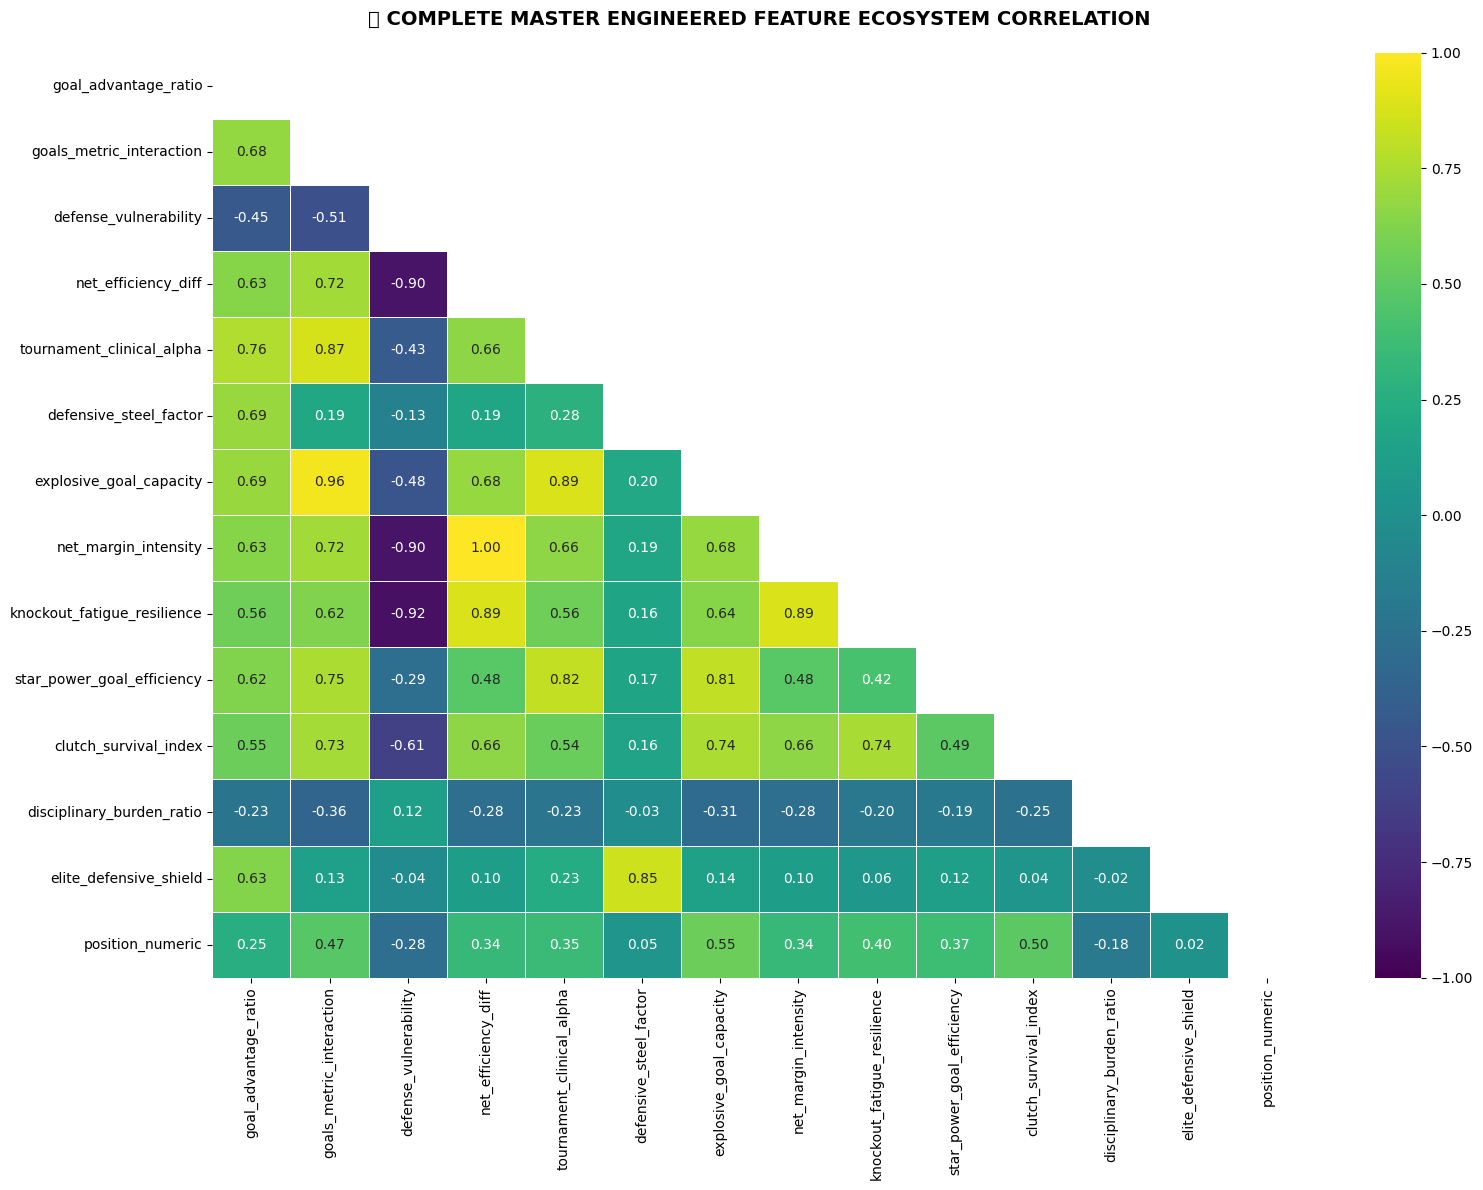


🎯 ALL ENGINEERED FEATURES RANKED BY IMPACT AGAINST POSITION_NUMERIC
position_numeric               1.000000
explosive_goal_capacity        0.551809
clutch_survival_index          0.499196
goals_metric_interaction       0.471486
knockout_fatigue_resilience    0.397640
star_power_goal_efficiency     0.373415
tournament_clinical_alpha      0.352591
net_margin_intensity           0.341560
net_efficiency_diff            0.341560
goal_advantage_ratio           0.250087
defensive_steel_factor         0.045144
elite_defensive_shield         0.018981
disciplinary_burden_ratio     -0.180679
defense_vulnerability         -0.281832


In [9]:
def build_complete_feature_matrix(df):
    """
    Engineers the complete set of historical baseline interactions 
    fused with next-gen relational database pillars.
    """
    X = df.copy()
    
    # ------------------------------------------------------------
    # PHASE 1: YOUR ORIGINAL ENGINEERED INTERACTIONS
    # ------------------------------------------------------------
    # Core ratios (safeguarded against division by zero)
    X['goals_per_match'] = X['total_goals_scored'] / (X['matches_played'] + 1e-5)
    X['conceded_per_match'] = X['total_goals_conceded'] / (X['matches_played'] + 1e-5)
    X['win_rate'] = X['total_wins'] / (X['matches_played'] + 1e-5)
    
    # Advanced structural metrics
    X['goal_advantage_ratio'] = (X['total_goals_scored'] + 1) / (X['total_goals_conceded'] + 1)
    X['goals_metric_interaction'] = X['win_rate'] * X['goals_per_match']
    X['defense_vulnerability'] = X['conceded_per_match'] * (1.0 - X['win_rate'])
    X['net_efficiency_diff'] = X['goals_per_match'] - X['conceded_per_match']
    
    # Tournament specific thresholds
    X['tournament_clinical_alpha'] = X['goals_per_match'] * X['goal_difference']
    X['defensive_steel_factor'] = X['win_rate'] * (1.0 / (X['conceded_per_match'] + 1e-2))
    X['explosive_goal_capacity'] = X['total_goals_scored'] * X['win_rate']
    X['net_margin_intensity'] = X['goal_difference'] / (X['matches_played'] + 1e-5)
    X['knockout_fatigue_resilience'] = X['matches_played'] * (1.0 - X['defense_vulnerability'])

    # ------------------------------------------------------------
    # PHASE 2: NEXT-GEN RELATIONAL INTERACTION PILLARS
    # ------------------------------------------------------------
    # Handle optional columns seamlessly if they were missing or zeroed out
    for col in ['elite_awards_count', 'disciplinary_friction_index', 'penalty_clutch_factor']:
        if col not in X.columns:
            X[col] = 0.0

    # Star Power Efficiency (Do elite individuals yield higher goal frequency?)
    X['star_power_goal_efficiency'] = X['elite_awards_count'] * X['goals_per_match']
    
    # Clutch Survival Index (Fuses standard winning capacity with penalty shootout mastery)
    X['clutch_survival_index'] = X['win_rate'] * (1.0 + X['penalty_clutch_factor'])
    
    # Disciplinary Burden Ratio (How heavily do cards penalize a team's total scoring volume?)
    X['disciplinary_burden_ratio'] = X['disciplinary_friction_index'] / (X['total_goals_scored'] + 1.0)
    
    # Elite Defensive Shield (Does star quality protect or compensate for a leaky defense?)
    X['elite_defensive_shield'] = X['elite_awards_count'] / (X['conceded_per_match'] + 1e-5)
    
    return X

# Apply to your consolidated dataframe
print("⚙️ Processing master feature engineering matrix...")
master_featured_df = build_complete_feature_matrix(combined_df)

# ------------------------------------------------------------
# PHASE 3: CORRELATION HEATMAP GENERATION
# ------------------------------------------------------------
# Explicit lists of every feature built
all_engineered_features = [
    'goal_advantage_ratio', 'goals_metric_interaction', 'defense_vulnerability', 
    'net_efficiency_diff', 'tournament_clinical_alpha', 'defensive_steel_factor', 
    'explosive_goal_capacity', 'net_margin_intensity', 'knockout_fatigue_resilience',
    'star_power_goal_efficiency', 'clutch_survival_index', 'disciplinary_burden_ratio', 
    'elite_defensive_shield'
]

# Ensure target column is numerically prepared for linear mapping
if 'position' in master_featured_df.columns:
    master_featured_df['position_numeric'] = pd.to_numeric(master_featured_df['position'], errors='coerce').fillna(0)

target_col = 'position_numeric' if 'position_numeric' in master_featured_df.columns else 'total_goals_scored'
plot_cols = all_engineered_features + [target_col]

# Compute master correlations
master_corr = master_featured_df[plot_cols].corr()

# Plot complete heatmap matrix
plt.figure(figsize=(16, 12))
mask = np.triu(np.ones_like(master_corr, dtype=bool))

sns.heatmap(
    master_corr, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="viridis", # Visually clear for tracking dense multi-feature matrix blocks
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title("🏆 COMPLETE MASTER ENGINEERED FEATURE ECOSYSTEM CORRELATION", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Print out final performance table ranking
print("\n" + "=" * 70)
print(f"🎯 ALL ENGINEERED FEATURES RANKED BY IMPACT AGAINST {target_col.upper()}")
print("=" * 70)
print(master_corr[target_col].sort_values(ascending=False).to_string())
print("=" * 70)

In [10]:
 

def compile_master_feature_set(base_df):
    """
    Combines raw baselines, raw relational indicators, and all 
    engineered interaction metrics into a single unified matrix.
    """
    # 1. Run our complete feature engine function
    compiled_df = build_complete_feature_matrix(base_df)
    
    # 2. Define our explicit feature groups
    raw_baselines = [
        'total_goals_scored', 'total_goals_conceded', 'total_wins', 
        'total_losses', 'total_draws', 'matches_played', 
        'goal_difference', 'goals_per_match', 'conceded_per_match', 'win_rate'
    ]
    
    raw_relational_pillars = [
        'elite_awards_count', 'disciplinary_friction_index', 'penalty_clutch_factor'
    ]
    
    all_engineered_interactions = [
        'explosive_goal_capacity', 'clutch_survival_index', 'goals_metric_interaction', 
        'knockout_fatigue_resilience', 'star_power_goal_efficiency', 'tournament_clinical_alpha', 
        'net_margin_intensity', 'net_efficiency_diff', 'goal_advantage_ratio', 
        'defensive_steel_factor', 'elite_defensive_shield', 'disciplinary_burden_ratio', 
        'defense_vulnerability'
    ]
    
    # 3. Consolidate into one master feature list
    master_features_list = raw_baselines + raw_relational_pillars + all_engineered_interactions
    
    # Filter dataset to keep only the features we care about (plus keys/targets for tracking)
    tracking_cols = []
    for col in ['tournament_id', 'team_id', 'position', 'position_numeric']:
        if col in compiled_df.columns:
            tracking_cols.append(col)
            
    final_cols = tracking_cols + master_features_list
    master_matrix = compiled_df[final_cols].copy()
    
    # 4. Final Data Cleanliness Check: Handle any infs or nans resulting from division
    for col in master_features_list:
        master_matrix[col] = master_matrix[col].replace([np.inf, -np.inf], np.nan)
        # Impute with 0.0 to ensure LightGBM/XGBoost handle the absence of history gracefully
        master_matrix[col] = master_matrix[col].fillna(0.0)
        
    return master_matrix, master_features_list

# Execute the compilation
print(" Compiling master feature space...")
final_training_matrix, ultimate_features = compile_master_feature_set(master_featured_df)

print("\n" + "="*50)
print(f"MASTER COMPILATION COMPLETE!")
print(f"Total Observation Rows: {final_training_matrix.shape[0]}")
print(f"Total Unique Predictive Features: {len(ultimate_features)}")
print("="*50)
print("Ultimate Feature List Ready For Model Input:")
for idx, feat in enumerate(ultimate_features, 1):
    print(f"  {idx}. {feat}")

 Compiling master feature space...

MASTER COMPILATION COMPLETE!
Total Observation Rows: 625
Total Unique Predictive Features: 26
Ultimate Feature List Ready For Model Input:
  1. total_goals_scored
  2. total_goals_conceded
  3. total_wins
  4. total_losses
  5. total_draws
  6. matches_played
  7. goal_difference
  8. goals_per_match
  9. conceded_per_match
  10. win_rate
  11. elite_awards_count
  12. disciplinary_friction_index
  13. penalty_clutch_factor
  14. explosive_goal_capacity
  15. clutch_survival_index
  16. goals_metric_interaction
  17. knockout_fatigue_resilience
  18. star_power_goal_efficiency
  19. tournament_clinical_alpha
  20. net_margin_intensity
  21. net_efficiency_diff
  22. goal_advantage_ratio
  23. defensive_steel_factor
  24. elite_defensive_shield
  25. disciplinary_burden_ratio
  26. defense_vulnerability
